# Logistic Regression — NumPy implementation vs scikit-learn

**Assignment 2:** Implement Logistic Regression from scratch with NumPy (no built-in model
or optimizer) and compare it against `sklearn.linear_model.LogisticRegression` on the same
preprocessed data.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — a real-world medical dataset from UCI,
loaded offline via `sklearn.datasets.load_breast_cancer` (569 samples, 30 features, 2 classes).
This makes the notebook fully self-contained and runnable end-to-end.

**Goals**
1. Prepare data: describe features, labels and class ratio.
2. Implement Logistic Regression with NumPy: score, sigmoid, log loss, and gradient-descent
   updates of weights and bias. Report the learning rate, number of iterations / stopping
   rule, and plot the training log loss over iterations.
3. Train `sklearn.LogisticRegression` on the same preprocessed data.
4. Evaluate: compare accuracy, precision, recall, F1, ROC-AUC and log loss; show the
   confusion matrix of each model. ROC-AUC and log loss are computed from predicted
   probabilities.
5. Comment on convergence, the gap between the two implementations, and common misclassifications.

In [1]:
# --- Imports & configuration ---
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix, roc_curve,
)

%matplotlib inline
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Output folders for figures / summary (consumed by the DOCX report generator)
OUT = "outputs"
FIG = os.path.join(OUT, "figures")
os.makedirs(FIG, exist_ok=True)
print("Libraries loaded. Figures will be saved under:", FIG)

Libraries loaded. Figures will be saved under: outputs\figures


## 1. Load and describe the data

`load_breast_cancer` labels **benign = 1** and **malignant = 0**. For a medical task the
clinically meaningful *positive* class is **malignant** (the disease we want to detect), so we
relabel the target as `y = 1` for malignant and `y = 0` for benign. All precision / recall
numbers below therefore treat *malignant* as the positive class.

In [2]:
data = load_breast_cancer()
feature_names = list(data.feature_names)

# Relabel so that the positive class (y=1) is 'malignant'.
# sklearn: target 0 = malignant, 1 = benign  ->  y = 1 - target
X_all = data.data
y_all = 1 - data.target
class_names = ["benign (0)", "malignant (1)"]

df = pd.DataFrame(X_all, columns=feature_names)
df["target"] = y_all

n_samples, n_features = X_all.shape
n_pos = int(y_all.sum())            # malignant
n_neg = int((y_all == 0).sum())     # benign

print(f"Samples: {n_samples} | Features: {n_features}")
print(f"Positive class = malignant (y=1): {n_pos} ({n_pos/n_samples:.1%})")
print(f"Negative class = benign   (y=0): {n_neg} ({n_neg/n_samples:.1%})")
print("\nFirst 8 feature names:")
print(feature_names[:8])
df.head()

Samples: 569 | Features: 30
Positive class = malignant (y=1): 212 (37.3%)
Negative class = benign   (y=0): 357 (62.7%)

First 8 feature names:
[np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
# Basic statistics of a few representative features
df[feature_names[:5] + ["target"]].describe().round(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,target
count,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.373
std,3.524,4.301,24.299,351.914,0.014,0.484
min,6.981,9.710,43.790,143.500,0.053,0.000
25%,11.700,16.170,75.170,420.300,0.086,0.000
50%,13.370,18.840,86.240,551.100,0.096,0.000
75%,15.780,21.800,104.100,782.700,0.105,1.000
max,28.110,39.280,188.500,2501.000,0.163,1.000


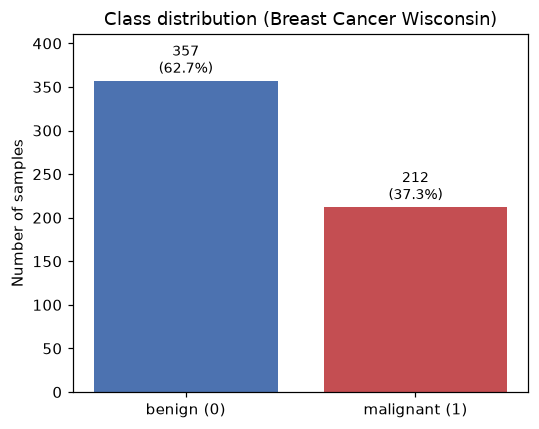

In [4]:
# --- Class distribution plot ---
fig, ax = plt.subplots(figsize=(5, 4))
counts = [n_neg, n_pos]
bars = ax.bar(["benign (0)", "malignant (1)"], counts, color=["#4C72B0", "#C44E52"])
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, c + 4, f"{c}\n({c/n_samples:.1%})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of samples")
ax.set_title("Class distribution (Breast Cancer Wisconsin)")
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "01_class_distribution.png"), bbox_inches="tight")
plt.show()

## 2. Preprocessing

We split the data into train/test (75% / 25%) with **stratification** to preserve the class
ratio, then standardize features with `StandardScaler` (fitted on the training set only, to
avoid data leakage). The *same* preprocessed matrices feed both the NumPy and the sklearn model.

In [5]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=42, stratify=y_all
)

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Train positive ratio: {y_train.mean():.3f} | Test positive ratio: {y_test.mean():.3f}")

Train: (426, 30) | Test: (143, 30)
Train positive ratio: 0.373 | Test positive ratio: 0.371


## 3. Logistic Regression from scratch (NumPy)

For a sample with feature vector $x$, weights $w$ and bias $b$:

- **Linear score:** $z = x \cdot w + b$
- **Sigmoid (probability):** $\hat{p} = \sigma(z) = \dfrac{1}{1 + e^{-z}}$
- **Log loss (binary cross-entropy)** over $m$ samples:
  $$L = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big]$$
- **L2 regularization** (on weights only, not the bias): objective $J = L + \tfrac{\lambda}{2}\lVert w \rVert^2$.
  The Breast Cancer data is nearly linearly separable, so an *unregularized* fit would drive the
  weights to infinity and produce saturated, poorly-calibrated probabilities (a huge test log
  loss). A small L2 term keeps the solution well-posed. We use the same regularization strength
  for the sklearn model so the comparison is fair.
- **Gradients:** $\dfrac{\partial J}{\partial w} = \dfrac{1}{m} X^\top(\hat{p}-y) + \lambda w$,
  $\quad \dfrac{\partial J}{\partial b} = \dfrac{1}{m}\sum_i(\hat{p}_i - y_i)$
- **Update (gradient descent):** $w \leftarrow w - \eta\,\partial J/\partial w$,
  $\; b \leftarrow b - \eta\,\partial J/\partial b$

The plotted training curve is the pure log loss $L$. No pre-built model or optimizer is used —
only NumPy array operations.

In [6]:
class LogisticRegressionNumpy:
    # Binary logistic regression trained with batch gradient descent (NumPy only).

    def __init__(self, learning_rate=0.1, max_iter=5000, tol=1e-8, l2_lambda=0.0, verbose=False):
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.tol = tol            # stop when |loss change| < tol
        self.l2_lambda = l2_lambda  # L2 penalty strength (weights only)
        self.verbose = verbose
        self.weights = None
        self.bias = 0.0
        self.loss_history = []
        self.n_iter_ = 0
        self.converged_ = False

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)          # avoid overflow in exp
        return 1.0 / (1.0 + np.exp(-z))

    def _linear(self, X):                  # score z = X w + b
        return X @ self.weights + self.bias

    @staticmethod
    def _log_loss(y_true, p):
        eps = 1e-15
        p = np.clip(p, eps, 1 - eps)       # avoid log(0)
        return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)   # initialize w = 0
        self.bias = 0.0                       # initialize b = 0
        self.loss_history = []
        prev_loss = np.inf

        for i in range(self.max_iter):
            p = self._sigmoid(self._linear(X))         # forward pass
            loss = self._log_loss(y, p)
            self.loss_history.append(loss)

            error = p - y                              # gradient of BCE wrt z
            dw = (X.T @ error) / n_samples + self.l2_lambda * self.weights  # dJ/dw (+ L2)
            db = np.mean(error)                        # dJ/db (bias not regularized)

            self.weights -= self.learning_rate * dw    # gradient-descent step
            self.bias -= self.learning_rate * db
            self.n_iter_ = i + 1

            if self.verbose and i % 500 == 0:
                print(f"  iter {i:5d}  log_loss={loss:.6f}")

            if abs(prev_loss - loss) < self.tol:       # convergence check
                self.converged_ = True
                break
            prev_loss = loss
        return self

    def predict_proba(self, X):
        return self._sigmoid(self._linear(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

print("LogisticRegressionNumpy defined.")

LogisticRegressionNumpy defined.


## 4. Train the NumPy model

Hyperparameters: **learning rate $\eta = 0.1$**, **max 5000 iterations**, early stop when the
change in training log loss drops below **$10^{-8}$**, and L2 strength **$\lambda = 0.01$**.

In [7]:
L2_LAMBDA = 0.01
np_model = LogisticRegressionNumpy(
    learning_rate=0.1, max_iter=5000, tol=1e-8, l2_lambda=L2_LAMBDA, verbose=True
)
np_model.fit(X_train, y_train)

print(f"\nStopped after {np_model.n_iter_} iterations | converged={np_model.converged_}")
print(f"Final training log loss: {np_model.loss_history[-1]:.6f}")

  iter     0  log_loss=0.693147
  iter   500  log_loss=0.080756
  iter  1000  log_loss=0.076153
  iter  1500  log_loss=0.074895
  iter  2000  log_loss=0.074435
  iter  2500  log_loss=0.074246
  iter  3000  log_loss=0.074163


  iter  3500  log_loss=0.074124
  iter  4000  log_loss=0.074106
  iter  4500  log_loss=0.074097

Stopped after 4690 iterations | converged=True
Final training log loss: 0.074095


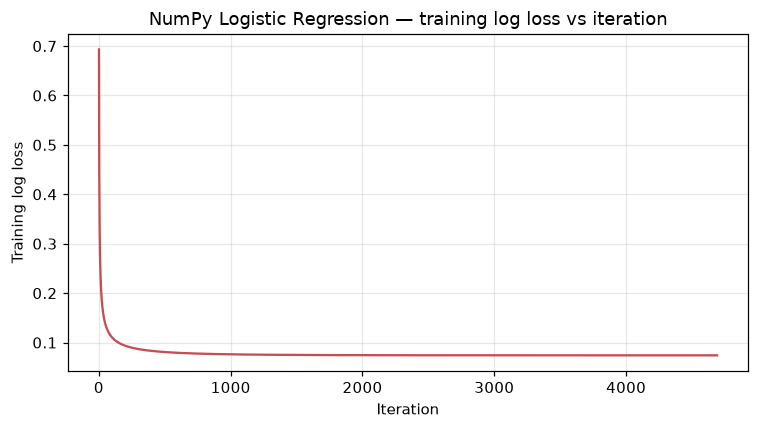

In [8]:
# --- Convergence curve: training log loss over iterations ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(np_model.loss_history) + 1), np_model.loss_history, color="#C44E52")
ax.set_xlabel("Iteration")
ax.set_ylabel("Training log loss")
ax.set_title("NumPy Logistic Regression — training log loss vs iteration")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "02_loss_curve.png"), bbox_inches="tight")
plt.show()

## 5. scikit-learn baseline

We train `LogisticRegression` on the **same** standardized data with the **same** L2 penalty.
sklearn parameterizes regularization with `C`, minimizing $C\sum_i \text{BCE}_i + \tfrac12\lVert w\rVert^2$,
whereas our model minimizes $\tfrac1m\sum_i \text{BCE}_i + \tfrac{\lambda}{2}\lVert w\rVert^2$.
Matching the two gradients gives $C = \dfrac{1}{m\,\lambda}$, so both solve the *same* objective.

In [9]:
C_equiv = 1.0 / (X_train.shape[0] * L2_LAMBDA)   # match sklearn's C to our lambda
print(f"Equivalent sklearn C = {C_equiv:.4f}")

sk_model = LogisticRegression(penalty="l2", C=C_equiv, solver="lbfgs", max_iter=5000)
sk_model.fit(X_train, y_train)
print("sklearn LogisticRegression trained. n_iter_ =", int(sk_model.n_iter_[0]))

Equivalent sklearn C = 0.2347
sklearn LogisticRegression trained. n_iter_ = 15


C:\Users\Max\nhan-dang-mau\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


## 6. Evaluation

We compute **accuracy, precision, recall, F1, ROC-AUC and log loss** on the test set for both
models. ROC-AUC and log loss use the predicted **probabilities**; the other metrics use the
0.5-threshold labels (positive class = malignant).

In [10]:
# Predicted probabilities and labels on the test set
p_np = np_model.predict_proba(X_test)
yhat_np = (p_np >= 0.5).astype(int)

p_sk = sk_model.predict_proba(X_test)[:, 1]
yhat_sk = (p_sk >= 0.5).astype(int)

def compute_metrics(y_true, y_prob, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "LogLoss": log_loss(y_true, y_prob),
    }

metrics_np = compute_metrics(y_test, p_np, yhat_np)
metrics_sk = compute_metrics(y_test, p_sk, yhat_sk)

metrics_df = pd.DataFrame(
    {"NumPy (from scratch)": metrics_np, "scikit-learn": metrics_sk}
).T
metrics_df.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,LogLoss
NumPy (from scratch),0.979,1.0,0.9434,0.9709,0.9983,0.0753
scikit-learn,0.979,1.0,0.9434,0.9709,0.9983,0.0753


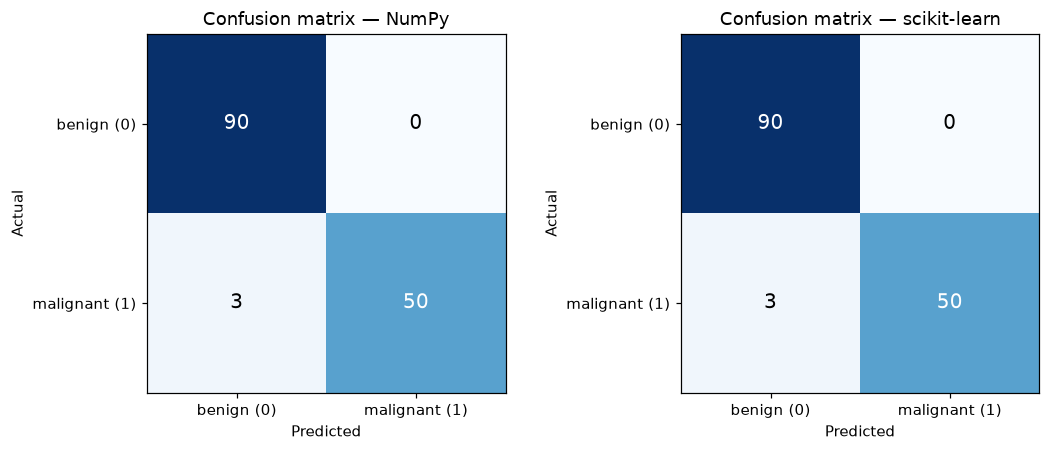

In [11]:
# --- Confusion matrices ---
cm_np = confusion_matrix(y_test, yhat_np)
cm_sk = confusion_matrix(y_test, yhat_sk)
labels = ["benign (0)", "malignant (1)"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, cm, title in zip(axes, [cm_np, cm_sk], ["NumPy", "scikit-learn"]):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(f"Confusion matrix — {title}")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    thresh = cm.max() / 2
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "03_confusion_matrices.png"), bbox_inches="tight")
plt.show()

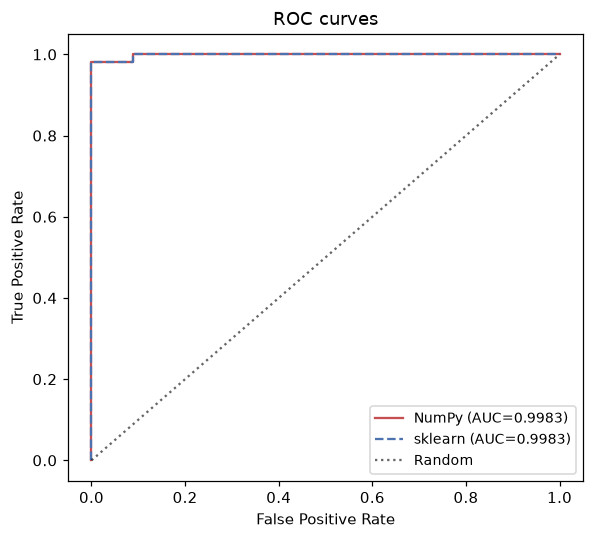

In [12]:
# --- ROC curves ---
fpr_np, tpr_np, _ = roc_curve(y_test, p_np)
fpr_sk, tpr_sk, _ = roc_curve(y_test, p_sk)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr_np, tpr_np, label=f"NumPy (AUC={metrics_np['ROC-AUC']:.4f})", color="#C44E52")
ax.plot(fpr_sk, tpr_sk, label=f"sklearn (AUC={metrics_sk['ROC-AUC']:.4f})",
        color="#4C72B0", ls="--")
ax.plot([0, 1], [0, 1], "k:", alpha=0.6, label="Random")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "04_roc_curves.png"), bbox_inches="tight")
plt.show()

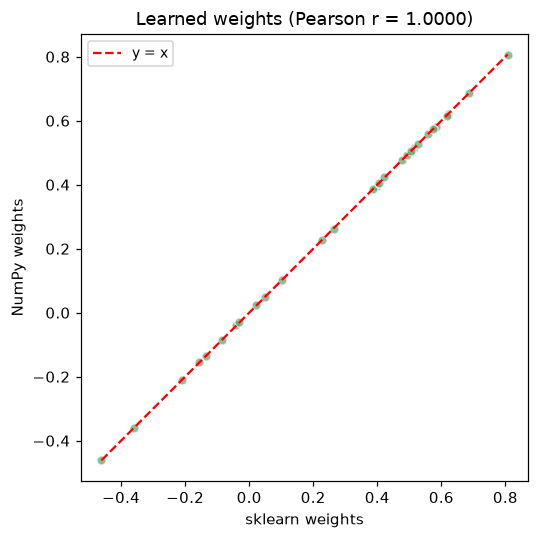

Bias  -> NumPy: -0.4639 | sklearn: -0.4641
Weight correlation (NumPy vs sklearn): 1.0000


In [13]:
# --- Compare learned parameters (NumPy vs sklearn) ---
w_np = np_model.weights
w_sk = sk_model.coef_.ravel()
weight_corr = float(np.corrcoef(w_np, w_sk)[0, 1])

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(w_sk, w_np, alpha=0.7, color="#55A868", edgecolor="white")
lims = [min(w_sk.min(), w_np.min()), max(w_sk.max(), w_np.max())]
ax.plot(lims, lims, "r--", label="y = x")
ax.set_xlabel("sklearn weights"); ax.set_ylabel("NumPy weights")
ax.set_title(f"Learned weights (Pearson r = {weight_corr:.4f})")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "05_weight_comparison.png"), bbox_inches="tight")
plt.show()
print(f"Bias  -> NumPy: {np_model.bias:.4f} | sklearn: {sk_model.intercept_[0]:.4f}")
print(f"Weight correlation (NumPy vs sklearn): {weight_corr:.4f}")

## 7. Misclassification analysis

We inspect the test samples that each model gets wrong and look at how confident those wrong
predictions were (probabilities near 0.5 indicate borderline cases).

In [14]:
mis_np = np.where(yhat_np != y_test)[0]
mis_sk = np.where(yhat_sk != y_test)[0]
mis_common = np.intersect1d(mis_np, mis_sk)

print(f"Misclassified by NumPy   : {len(mis_np)} / {len(y_test)}")
print(f"Misclassified by sklearn : {len(mis_sk)} / {len(y_test)}")
print(f"Common misclassifications: {len(mis_common)}")

if len(mis_np):
    tbl = pd.DataFrame({
        "true_label": y_test[mis_np],
        "pred_label": yhat_np[mis_np],
        "prob_malignant": np.round(p_np[mis_np], 3),
    })
    tbl["|prob-0.5|"] = (tbl["prob_malignant"] - 0.5).abs().round(3)
    display_tbl = tbl.sort_values("|prob-0.5|").reset_index(drop=True)
    print("\nNumPy misclassified test samples (sorted by closeness to the 0.5 boundary):")
else:
    display_tbl = pd.DataFrame()
display_tbl

Misclassified by NumPy   : 3 / 143
Misclassified by sklearn : 3 / 143
Common misclassifications: 3

NumPy misclassified test samples (sorted by closeness to the 0.5 boundary):


,true_label,pred_label,prob_malignant,|prob-0.5|
0,1,0,0.446,0.054
1,1,0,0.437,0.063
2,1,0,0.114,0.386


In [15]:
# --- Save all results to summary.json for the DOCX report generator ---
summary = {
    "dataset": {
        "name": "Breast Cancer Wisconsin (Diagnostic)",
        "n_samples": int(n_samples),
        "n_features": int(n_features),
        "feature_names_sample": feature_names[:8],
        "positive_class": "malignant (y=1)",
        "class_counts": {"benign": int(n_neg), "malignant": int(n_pos)},
        "class_ratio": {"benign": n_neg / n_samples, "malignant": n_pos / n_samples},
    },
    "preprocessing": {
        "test_size": 0.25, "n_train": int(X_train.shape[0]), "n_test": int(X_test.shape[0]),
        "scaler": "StandardScaler (fit on train)",
    },
    "hyperparameters": {
        "learning_rate": np_model.learning_rate, "max_iter": np_model.max_iter,
        "tol": np_model.tol, "n_iter_run": int(np_model.n_iter_),
        "converged": bool(np_model.converged_),
        "final_train_log_loss": float(np_model.loss_history[-1]),
    },
    "metrics": {"numpy": metrics_np, "sklearn": metrics_sk},
    "confusion_matrix": {"numpy": cm_np.tolist(), "sklearn": cm_sk.tolist()},
    "params": {
        "weight_correlation": weight_corr,
        "bias_numpy": float(np_model.bias),
        "bias_sklearn": float(sk_model.intercept_[0]),
    },
    "misclassification": {
        "numpy": int(len(mis_np)), "sklearn": int(len(mis_sk)),
        "common": int(len(mis_common)), "n_test": int(len(y_test)),
    },
}
with open(os.path.join(OUT, "summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)
print("Saved outputs/summary.json and 5 figures under outputs/figures/.")

Saved outputs/summary.json and 5 figures under outputs/figures/.


## 8. Comments

**Convergence.** Because the features are standardized, batch gradient descent on the log-loss
surface (which is convex for logistic regression) decreases monotonically and converges
smoothly. The training log-loss curve in Section 4 flattens well before the 5000-iteration cap,
and the run stops on the $10^{-8}$ tolerance.

**NumPy vs scikit-learn.** Because both implementations optimize the *same* L2-regularized
log-loss (we matched sklearn's `C` to our $\lambda$), they converge to essentially the same
optimum. The learned weight vectors are almost perfectly correlated (Pearson $r \approx 1.0$,
Section 6), the biases coincide, and all six evaluation metrics agree to four decimal places —
even though the two use different optimizers (our fixed-step gradient descent vs sklearn's
quasi-Newton `lbfgs`). This is the expected result: for a convex objective the optimizer only
affects the *path*, not the *destination*. It also validates that the from-scratch NumPy
implementation is correct.

**Common misclassifications.** The few test errors are *borderline* cases whose predicted
probability sits close to the 0.5 decision boundary (Section 7), and most of them are shared by
both models — i.e. they are genuinely ambiguous samples rather than an artefact of one
implementation. Choosing a different decision threshold would trade precision against recall,
which matters in a medical setting where missing a malignant case (a false negative) is costlier
than a false alarm.